# Proyecto P05: Dashboard de COVID-19 — Solución
Presenta: Juliho Castillo Colmenares

Enunciado para estudiantes: [p05-dashboard-covid-guia.ipynb](p05-dashboard-covid-guia.ipynb) · App: [p05-dashboard-covid-app.py](p05-dashboard-covid-app.py)

## Contexto

Una organización de salud pública quiere un tablero de una página que compare la pandemia de COVID-19 por país: más contagios, más muertes, mayor y menor tasa de mortalidad y mayor tasa de recuperación. Aquí se preparan las series con pandas, se comprueban las medidas con DuckDB, se revisan los problemas de los datos y se construye la app de Streamlit. El enunciado original del curso se perdió; las instrucciones de la guía se reconstruyeron a partir de la solución.

Fuente: [COVID-19 Data Repository](https://github.com/CSSEGISandData/COVID-19) del Centro de Ciencia e Ingeniería de Sistemas (CSSE) de la Universidad Johns Hopkins, series de tiempo globales (`csse_covid_19_data/csse_covid_19_time_series/`). El repositorio se archivó en marzo de 2023 y sus datos se publican con licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). La copia local está en [`datos/`](datos/).

In [1]:
import logging
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

DATOS = Path("datos")
ARCHIVOS = {"confirmados": "casos-confirmados.csv", "muertes": "muertes.csv", "recuperados": "recuperados.csv"}
DESCRIPTIVAS = ["Province/State", "Country/Region", "Lat", "Long"]

### Tarea 1. Importar las series

In [2]:
anchos = {medida: pd.read_csv(DATOS / archivo) for medida, archivo in ARCHIVOS.items()}
for medida, ancho in anchos.items():
    fechas = ancho.columns[len(DESCRIPTIVAS):]
    print(f"{medida:12} {len(ancho)} filas, {len(fechas)} fechas ({fechas[0]} a {fechas[-1]}), "
          f"{ancho['Country/Region'].nunique()} países o regiones")
anchos["confirmados"].iloc[:5, :8]

confirmados  289 filas, 1143 fechas (1/22/20 a 3/9/23), 201 países o regiones
muertes      289 filas, 1143 fechas (1/22/20 a 3/9/23), 201 países o regiones
recuperados  274 filas, 1143 fechas (1/22/20 a 3/9/23), 201 países o regiones


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0
1,NaN,Albania,41.15330,20.168300,0,0,0,0
2,NaN,Algeria,28.03390,1.659600,0,0,0,0
3,NaN,Andorra,42.50630,1.521800,0,0,0,0
4,NaN,Angola,-11.20270,17.873900,0,0,0,0


In [3]:
def filas(ancho):
    return set(zip(ancho["Province/State"].fillna(""), ancho["Country/Region"]))


print("Confirmados y muertes tienen las mismas filas:", filas(anchos["confirmados"]) == filas(anchos["muertes"]))
solo_conf = filas(anchos["confirmados"]) - filas(anchos["recuperados"])
solo_rec = filas(anchos["recuperados"]) - filas(anchos["confirmados"])
print("Filas de confirmados que no están en recuperados:", len(solo_conf), "de", sorted({p for _, p in solo_conf}))
print("Filas de recuperados que no están en confirmados:", sorted(solo_rec))

Confirmados y muertes tienen las mismas filas: True
Filas de confirmados que no están en recuperados: 16 de ['Canada']
Filas de recuperados que no están en confirmados: [('', 'Canada')]


Confirmados y muertes tienen las mismas 289 filas, pero recuperados solo 274: Canadá aparece en 16 filas de provincia en los dos primeros archivos (incluidas `Diamond Princess`, `Grand Princess` y `Repatriated Travellers`) y en una sola fila sin provincia en el de recuperados. Los tres archivos tienen 201 países o regiones.

### Tarea 2. Pasar del formato ancho al largo

In [4]:
def a_largo(ancho, medida):
    largo = ancho.melt(id_vars=DESCRIPTIVAS, var_name="fecha", value_name=medida)
    largo["fecha"] = pd.to_datetime(largo["fecha"], format="%m/%d/%y")
    largo["Province/State"] = largo["Province/State"].fillna("")
    return largo


largos = {medida: a_largo(ancho, medida) for medida, ancho in anchos.items()}
for medida, largo in largos.items():
    print(f"{medida:12} {len(largo):,} filas; valores nulos: {largo[medida].isna().sum()}; "
          f"fechas: {largo['fecha'].nunique()} ({largo['fecha'].min():%Y-%m-%d} a {largo['fecha'].max():%Y-%m-%d})".replace(",", " "))
largos["confirmados"].head()

confirmados  330 327 filas; valores nulos: 0; fechas: 1143 (2020-01-22 a 2023-03-09)
muertes      330 327 filas; valores nulos: 0; fechas: 1143 (2020-01-22 a 2023-03-09)
recuperados  313 182 filas; valores nulos: 0; fechas: 1143 (2020-01-22 a 2023-03-09)


,Province/State,Country/Region,Lat,Long,fecha,confirmados
0,,Afghanistan,33.93911,67.709953,2020-01-22,0
1,,Albania,41.15330,20.168300,2020-01-22,0
2,,Algeria,28.03390,1.659600,2020-01-22,0
3,,Andorra,42.50630,1.521800,2020-01-22,0
4,,Angola,-11.20270,17.873900,2020-01-22,0


In [5]:
# Sin el fillna, groupby descarta por defecto las claves nulas
sin_relleno = anchos["confirmados"].groupby(["Country/Region", "Province/State"]).size()
con_relleno = largos["confirmados"].groupby(["Country/Region", "Province/State"]).size()
print("Grupos sin rellenar Province/State:", len(sin_relleno), "· rellenando con '':", len(con_relleno))

Grupos sin rellenar Province/State: 91 · rellenando con '': 289


Cada archivo pasa a 1143 filas por provincia (330 327 en confirmados y muertes, 313 182 en recuperados), sin valores nulos en la medida y con fechas del 22 de enero de 2020 al 9 de marzo de 2023. El `fillna("")` no es cosmético: sin él, `groupby` deja fuera las 198 filas sin provincia (entre ellas las de Estados Unidos, India o Brasil) y solo quedan 91 de los 289 grupos.

### Tarea 3. Combinar en una sola tabla

Primero, el intento ingenuo: unir por provincia, país y fecha, como se haría con dos combinaciones izquierdas en una herramienta de BI.

In [6]:
claves = ["Province/State", "Country/Region", "fecha"]
ingenua = (
    largos["confirmados"]
    .merge(largos["muertes"][claves + ["muertes"]], on=claves, how="left")
    .merge(largos["recuperados"][claves + ["recuperados"]], on=claves, how="left")
)
canada = ingenua[ingenua["Country/Region"] == "Canada"]
rec_canada = largos["recuperados"].query("`Country/Region` == 'Canada'")["recuperados"].max()
print(f"Filas: {len(ingenua):,}; filas sin recuperados: {ingenua['recuperados'].isna().sum():,}".replace(",", " "))
print(f"Canadá: {canada['recuperados'].notna().sum()} filas con recuperados en la unión; "
      f"el archivo de recuperados le da {rec_canada:,}".replace(",", " "))

# Las coordenadas tampoco sirven como clave: no coinciden en todas las filas
coordenadas = anchos["confirmados"][DESCRIPTIVAS].merge(
    anchos["recuperados"][DESCRIPTIVAS], on=["Province/State", "Country/Region"], suffixes=("", "_rec")
)
distintas = ~(np.isclose(coordenadas["Lat"], coordenadas["Lat_rec"], atol=1e-3, equal_nan=True)
              & np.isclose(coordenadas["Long"], coordenadas["Long_rec"], atol=1e-3, equal_nan=True))
coordenadas[distintas]

Filas: 330 327; filas sin recuperados: 18 288
Canadá: 0 filas con recuperados en la unión; el archivo de recuperados le da 1 405 971


,Province/State,Country/Region,Lat,Long,Lat_rec,Long_rec
52,Hebei,China,39.5490,116.1306,37.8957,114.9042
54,Henan,China,37.8957,114.9042,33.8820,113.6140


La unión por provincia deja 18 288 filas sin recuperados (las 16 filas de Canadá por 1143 días) y Canadá se queda sin un solo recuperado, aunque el archivo de recuperados le asigna 1 405 971 en su fila única. Además, Hebei y Henan tienen coordenadas distintas en los dos archivos, así que `Lat`/`Long` tampoco sirven como clave.

La solución es **agregar a nivel país antes de unir**. Como cada serie es acumulada, el valor de un país en una fecha es la suma, por provincia, del máximo alcanzado hasta esa fecha (`cummax`). Usar el máximo acumulado y no el valor del día protege de las correcciones a la baja y de los ceros que aparecen en recuperados a partir de agosto de 2021 (Tarea 5).

In [7]:
def por_pais_y_dia(largo, medida):
    # Valor diario de cada país: suma, por provincia, del máximo acumulado hasta ese día
    largo = largo.sort_values("fecha")
    acumulado = largo.groupby(["Country/Region", "Province/State"])[medida].cummax()
    return (
        largo.assign(**{medida: acumulado})
        .groupby(["Country/Region", "fecha"], as_index=False)[medida].sum()
    )


clave_pais = ["Country/Region", "fecha"]
covid = (
    por_pais_y_dia(largos["confirmados"], "confirmados")
    .merge(por_pais_y_dia(largos["muertes"], "muertes"), on=clave_pais, how="outer", validate="one_to_one")
    .merge(por_pais_y_dia(largos["recuperados"], "recuperados"), on=clave_pais, how="outer", validate="one_to_one")
    .rename(columns={"Country/Region": "pais"})
)
print(f"{len(covid):,} filas = {covid['pais'].nunique()} países x {covid['fecha'].nunique()} días; "
      f"valores nulos: {covid.isna().sum().sum()}".replace(",", " "))
covid[covid["pais"] == "Canada"].iloc[[-1]]

229 743 filas = 201 países x 1143 días; valores nulos: 0


,pais,fecha,confirmados,muertes,recuperados
38861,Canada,2023-03-09,4617096,51720,1405971


`covid` tiene una fila por país y día (201 × 1143), sin nulos, y Canadá conserva sus recuperados.

### Tarea 4. Medidas por país

La medida original: máximo de cada provincia hasta la fecha de corte y suma por país, primero en pandas y después en DuckDB con dos niveles de agregación.

In [8]:
def total_por_pais(largo, medida, corte):
    hasta = largo[largo["fecha"] <= corte]
    por_provincia = hasta.groupby(["Country/Region", "Province/State"])[medida].max()
    return por_provincia.groupby("Country/Region").sum()


con = duckdb.connect()
for medida, largo in largos.items():
    con.register(medida, largo.rename(columns={"Country/Region": "pais", "Province/State": "provincia", medida: "valor"}))


def sql_total(tabla):
    return f'''
        SELECT pais, SUM(maximo) AS total
        FROM (
            SELECT pais, provincia, MAX(valor) AS maximo   -- nivel 1: provincia
            FROM {tabla}
            WHERE fecha <= $corte
            GROUP BY pais, provincia
        )
        GROUP BY pais                                      -- nivel 2: país
    '''


def total_sql(medida, corte):
    resultado = con.execute(sql_total(medida), {"corte": corte.to_pydatetime()}).df()
    return resultado.set_index("pais")["total"].sort_index()


ULTIMA = largos["confirmados"]["fecha"].max()
mundo_rec = largos["recuperados"].groupby("fecha")["recuperados"].sum()
ULTIMA_REC = mundo_rec[mundo_rec > 0].index.max()
print("Última fecha:", ULTIMA.date(), "· último día con recuperados:", ULTIMA_REC.date())

for medida, corte in [("confirmados", ULTIMA), ("muertes", ULTIMA), ("recuperados", ULTIMA_REC)]:
    con_pandas = total_por_pais(largos[medida], medida, corte)
    con_sql = total_sql(medida, corte)
    de_covid = covid[covid["fecha"] == corte].set_index("pais")[medida].sort_index()
    pd.testing.assert_series_equal(con_pandas, con_sql, check_names=False, check_dtype=False)
    pd.testing.assert_series_equal(con_pandas, de_covid, check_names=False, check_dtype=False)
    print(f"{medida:12} al {corte:%Y-%m-%d}: pandas = DuckDB = covid; total mundial {con_pandas.sum():,}".replace(",", " "))

Última fecha:

 2023-03-09 · último día con recuperados: 2021-08-04
confirmados  al 2023-03-09: pandas = DuckDB = covid; total mundial 676 575 751


muertes      al 2023-03-09: pandas = DuckDB = covid; total mundial 6 882 143
recuperados  al 2021-08-04: pandas = DuckDB = covid; total mundial 137 254 523


Las tres formas coinciden exactamente para los 201 países. Las tasas usan división segura: en SQL, `NULLIF` convierte el denominador 0 en `NULL`, y la división da `NULL` en lugar de error.

In [9]:
mortalidad_sql = con.execute(f'''
    WITH c AS ({sql_total("confirmados")}), m AS ({sql_total("muertes")})
    SELECT pais, c.total AS confirmados, m.total AS muertes,
           100 * m.total / NULLIF(c.total, 0) AS mortalidad
    FROM c JOIN m USING (pais)
    ORDER BY pais
''', {"corte": ULTIMA.to_pydatetime()}).df().set_index("pais")


def tabla_por_pais(corte):
    # Recuperados y sus confirmados, a la misma fecha: la serie de recuperados se detiene
    fecha_rec = min(corte, ULTIMA_REC)
    tabla = pd.DataFrame({
        "confirmados": total_por_pais(largos["confirmados"], "confirmados", corte),
        "muertes": total_por_pais(largos["muertes"], "muertes", corte),
        "confirmados_a_fecha_rec": total_por_pais(largos["confirmados"], "confirmados", fecha_rec),
        "recuperados": total_por_pais(largos["recuperados"], "recuperados", fecha_rec),
    })
    tabla["mortalidad"] = 100 * tabla["muertes"] / tabla["confirmados"].where(tabla["confirmados"] > 0)
    tabla["recuperacion"] = 100 * tabla["recuperados"] / tabla["confirmados_a_fecha_rec"].where(
        tabla["confirmados_a_fecha_rec"] > 0
    )
    return tabla.rename_axis("pais")


por_pais = tabla_por_pais(ULTIMA)
pd.testing.assert_series_equal(por_pais["mortalidad"], mortalidad_sql["mortalidad"], check_names=False)
print("Mortalidad: pandas = DuckDB")
por_pais.loc[["US", "India", "Canada", "Korea, North"]].round(2)

Mortalidad: pandas = DuckDB


,confirmados,muertes,confirmados_a_fecha_rec,recuperados,mortalidad,recuperacion
pais,,,,,,
US,103802702,1123836,35460776,6298082,1.08,17.76
India,44690738,530779,31812114,30974748,1.19,97.37
Canada,4617096,51720,1438807,1405971,1.12,97.72
"Korea, North",1,6,0,0,600.00,NaN


`tabla_por_pais` es la misma que usa la app. Corea del Norte ya avisa de un problema: 1 caso confirmado y 6 muertes dan una mortalidad del 600 %.

### Tarea 5. Revisar los problemas de los datos

**1. La serie de recuperados se detiene.**

            confirmados  muertes  recuperados
fecha                                        
2021-08-02    199443855  4262171    130277533
2021-08-03    200078130  4272524    130582001
2021-08-04    200758588  4283016    130899061
2021-08-05    201444210  4294008            0
2021-08-06    202263736  4304479            0
Valores distintos de 0 después: 8 [['Pitcairn Islands', 'United Kingdom', -1]]


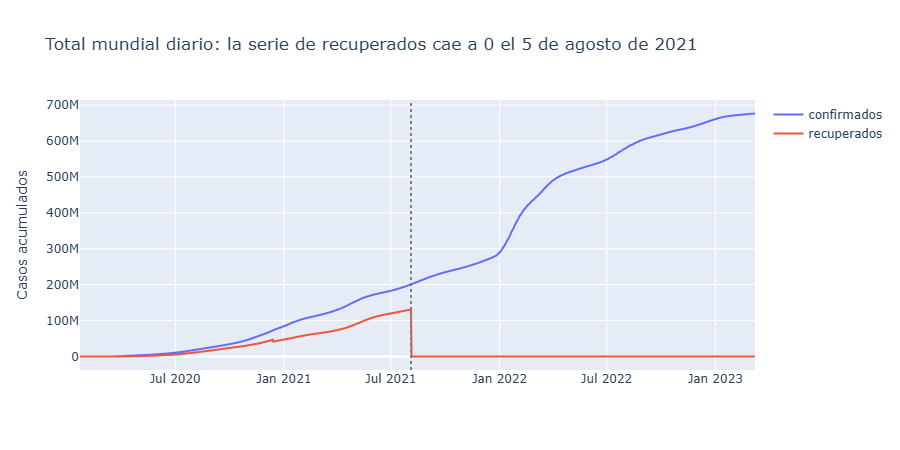

In [10]:
mundo = pd.DataFrame({medida: largos[medida].groupby("fecha")[medida].sum() for medida in ARCHIVOS})
print(mundo.loc["2021-08-02":"2021-08-06"].to_string())
despues = largos["recuperados"][(largos["recuperados"]["fecha"] > ULTIMA_REC) & (largos["recuperados"]["recuperados"] != 0)]
print("Valores distintos de 0 después:", len(despues), despues[["Province/State", "Country/Region", "recuperados"]].drop_duplicates().values.tolist())

figura = px.line(
    mundo[["confirmados", "recuperados"]].reset_index().melt(id_vars="fecha", var_name="serie", value_name="casos"),
    x="fecha", y="casos", color="serie",
    title="Total mundial diario: la serie de recuperados cae a 0 el 5 de agosto de 2021",
    labels={"fecha": "", "casos": "Casos acumulados", "serie": ""},
)
figura.add_vline(x=ULTIMA_REC, line_dash="dot", line_color="gray")
figura.show()

El último día con recuperados es el 4 de agosto de 2021; desde el día siguiente todos los valores son 0 (salvo 8 días con −1 en Pitcairn, en septiembre de 2022). La caída de mediados de diciembre de 2020 en la gráfica es Estados Unidos, cuya fila de recuperados vuelve a 0 después del 13 de diciembre de 2020. Por eso las medidas usan el máximo, y la tasa de recuperación se calcula con los confirmados **a la misma fecha** que los recuperados. Si se dividiera entre los confirmados de 2023, la tasa se hundiría:

In [11]:
comparacion = por_pais.loc[["India", "Germany", "Brazil", "Canada"], ["recuperados", "confirmados_a_fecha_rec", "confirmados", "recuperacion"]]
comparacion["recuperacion_con_confirmados_2023"] = 100 * comparacion["recuperados"] / comparacion["confirmados"]
comparacion.round(2)

,recuperados,confirmados_a_fecha_rec,confirmados,recuperacion,recuperacion_con_confirmados_2023
pais,,,,,
India,30974748,31812114,44690738,97.37,69.31
Germany,3659260,3777446,38249060,96.87,9.57
Brazil,17771228,20034407,37081209,88.70,47.93
Canada,1405971,1438807,4617096,97.72,30.45


In [12]:
# Países cuya serie de recuperados dejó de crecer mucho antes del 4 de agosto de 2021
rec_diario = covid.pivot(index="fecha", columns="pais", values="recuperados").loc[:ULTIMA_REC]
ultimo_aumento = rec_diario.diff().gt(0).apply(lambda serie: serie[serie].index.max())
atrasados = por_pais.assign(ultimo_aumento=ultimo_aumento)
atrasados = atrasados[(atrasados["recuperados"] > 0) & (atrasados["ultimo_aumento"] < ULTIMA_REC - pd.Timedelta(days=30))]
print(len(atrasados), "entradas con recuperados que llevaban más de 30 días sin aumentar; las de al menos 100 000 casos:")
grandes = atrasados[atrasados["confirmados_a_fecha_rec"] >= 100_000]
grandes[["recuperados", "confirmados_a_fecha_rec", "recuperacion", "ultimo_aumento"]].sort_values("ultimo_aumento").round(2)

26 entradas con recuperados que llevaban más de 30 días sin aumentar; las de al menos 100 000 casos:


,recuperados,confirmados_a_fecha_rec,recuperacion,ultimo_aumento
pais,,,,
Spain,150376,4545184,3.31,2020-05-18
Ireland,23364,305527,7.65,2020-06-24
Serbia,15564,723518,2.15,2020-07-19
Belgium,31130,1132934,2.75,2020-11-11
Norway,17998,139218,12.93,2020-11-16
Greece,93764,503885,18.61,2020-12-04
US,6298082,35460776,17.76,2020-12-13
Switzerland,317600,721776,44.00,2020-12-27
Slovakia,255300,776716,32.87,2021-02-12


Algunos países dejaron de informar recuperados mucho antes que el resto (por ejemplo, España en mayo de 2020, Bélgica en noviembre de 2020 o Estados Unidos en diciembre de 2020), así que su tasa es artificialmente baja. En un ranking de *mayor* recuperación quedan al final y no lo distorsionan; la app muestra la fecha del último aumento de cada país para que se note.

**2. Países que nunca informaron recuperados.**

In [13]:
sin_recuperados = por_pais[por_pais["recuperados"] == 0]
print(len(sin_recuperados), "entradas sin ningún recuperado:", sin_recuperados.index.tolist())

10 entradas sin ningún recuperado: ['Antarctica', 'Kiribati', 'Korea, North', 'Nauru', 'Palau', 'Summer Olympics 2020', 'Sweden', 'Tonga', 'Tuvalu', 'Winter Olympics 2022']


Su tasa sería 0 %, pero no porque nadie se recuperara sino porque no hay datos (Suecia es el caso más visible). Se excluyen del ranking de recuperación.

**3. Entradas que no son países.**

In [14]:
NO_PAISES = ["Diamond Princess", "MS Zaandam", "Summer Olympics 2020", "Winter Olympics 2022", "Antarctica"]
print(por_pais.loc[NO_PAISES, ["confirmados", "muertes", "recuperados", "mortalidad"]].round(2).to_string())

ultimo_dia = anchos["confirmados"].columns[-1]
sin_coordenadas = anchos["confirmados"]["Lat"].isna() | ((anchos["confirmados"]["Lat"] == 0) & (anchos["confirmados"]["Long"] == 0))
anchos["confirmados"].loc[sin_coordenadas, DESCRIPTIVAS + [ultimo_dia]]

                      confirmados  muertes  recuperados  mortalidad
pais                                                               
Diamond Princess              712       13          699        1.83
MS Zaandam                      9        2            7       22.22
Summer Olympics 2020          865        0            0        0.00
Winter Olympics 2022          535        0            0        0.00
Antarctica                     11        0            0        0.00


,Province/State,Country/Region,Lat,Long,3/9/23
42,Diamond Princess,Canada,0.0,0.0,0
43,Grand Princess,Canada,0.0,0.0,13
53,Repatriated Travellers,Canada,NaN,NaN,13
89,Unknown,China,NaN,NaN,1521816
106,NaN,Diamond Princess,0.0,0.0,712
175,NaN,MS Zaandam,0.0,0.0,9


Las cinco entradas de `Country/Region` que no son países (dos cruceros, dos Juegos Olímpicos y la Antártida) se excluyen de los rankings. Las filas de provincia sin coordenadas, en cambio, son casos atribuidos a un país (`Canada` / `Diamond Princess`, `Grand Princess`, `Repatriated Travellers`; `China` / `Unknown`, con 1 521 816 confirmados) y se quedan dentro del total de su país; solo se descartan del mapa.

**4. Tasas con pocos casos.**

In [15]:
MINIMO = 10_000
print(por_pais.nlargest(5, "mortalidad")[["confirmados", "muertes", "mortalidad"]].round(2).to_string())
paises = por_pais.drop(index=NO_PAISES)
print(f"\nPaíses con al menos {MINIMO:,} casos: {(paises['confirmados'] >= MINIMO).sum()} de {len(paises)}".replace(",", " "))

              confirmados  muertes  mortalidad
pais                                          
Korea, North            1        6      600.00
MS Zaandam              9        2       22.22
Yemen               11945     2159       18.07
Sudan               63829     5017        7.86
Syria               57467     3164        5.51

Países con al menos 10 000 casos: 180 de 196


Sin filtro, el primer lugar en mortalidad es Corea del Norte (6 muertes con 1 caso confirmado: la cifra oficial de confirmados no es creíble) y el segundo un crucero con 9 casos. Con pocos casos, una sola muerte mueve la tasa decenas de puntos, así que los rankings de tasas exigen al menos 10 000 casos confirmados (en la app, el mínimo se elige en la barra lateral). Con ese umbral entran 180 de los 196 países.

**5. Acumulados que bajan.**

In [16]:
for medida, largo in largos.items():
    largo = largo.sort_values("fecha")
    cambio = largo.groupby(["Country/Region", "Province/State"])[medida].diff()
    series_con_bajada = largo.loc[cambio < 0, ["Country/Region", "Province/State"]].drop_duplicates()
    print(f"{medida:12} {(cambio < 0).sum()} bajadas de un día a otro en {len(series_con_bajada)} series")

conf = largos["confirmados"]
maximo = conf.groupby(["Country/Region", "Province/State"])["confirmados"].max()
ultimo = conf[conf["fecha"] == ULTIMA].set_index(["Country/Region", "Province/State"])["confirmados"]
diferencia = (maximo - ultimo)[lambda d: d != 0].sort_values(ascending=False)
print("\nConfirmados: máximo menos último valor, en las provincias donde difieren")
print(diferencia.to_string())

confirmados  362 bajadas de un día a otro en 128 series

muertes      291 bajadas de un día a otro en 106 series


recuperados  555 bajadas de un día a otro en 259 series

Confirmados: máximo menos último valor, en las provincias donde difieren
Country/Region       Province/State  
Brazil                                   5156
Congo (Brazzaville)                       288
Netherlands          Aruba                101
China                Macau                 33
Tuvalu                                     23
Canada               Diamond Princess       1


Las series acumuladas bajan a veces por correcciones (por ejemplo, casos duplicados que se retiran). Usar el máximo, como la medida original, toma el pico y no la cifra corregida, pero el efecto en los totales es mínimo: en confirmados, solo 6 series terminan por debajo de su máximo, y la mayor diferencia (Brasil, 5156 casos) es menos del 0,02 % de sus 37 millones. En recuperados, en cambio, el máximo es imprescindible por los ceros de después de agosto de 2021.

### Tarea 6. Rankings

In [17]:
def rankings(tabla, n=10, minimo=MINIMO):
    paises = tabla[~tabla.index.isin(NO_PAISES)]
    # Los filtros van antes de ordenar: así no entran países con pocos casos ni tasas vacías
    elegibles = paises[(paises["confirmados"] >= max(minimo, 1)) & paises["mortalidad"].notna()]
    recuperacion = paises[(paises["confirmados_a_fecha_rec"] >= max(minimo, 1)) & (paises["recuperados"] > 0)]
    return {
        "Países con más contagios": paises.nlargest(n, "confirmados")[["confirmados"]],
        "Países con más decesos": paises.nlargest(n, "muertes")[["muertes"]],
        "Países con mayor tasa de mortalidad": elegibles.nlargest(n, "mortalidad")[["mortalidad", "confirmados"]],
        "Países con menor tasa de mortalidad": elegibles.nsmallest(n, "mortalidad")[["mortalidad", "confirmados"]],
        "Países con mayor índice de recuperación": recuperacion.nlargest(n, "recuperacion")[["recuperacion"]],
    }


tablas = rankings(por_pais)
for titulo, tabla in tablas.items():
    print(titulo)
    display(tabla.round(2))

Países con más contagios


,confirmados
pais,
US,103802702
India,44690738
France,39866718
Germany,38249060
Brazil,37081209
Japan,33320438
"Korea, South",30615522
Italy,25603510
United Kingdom,24658705


Países con más decesos


,muertes
pais,
US,1123836
Brazil,699276
India,530779
Russia,388478
Mexico,333188
United Kingdom,220725
Peru,219539
Italy,188322
Germany,168935


Países con mayor tasa de mortalidad


,mortalidad,confirmados
pais,,
Yemen,18.07,11945
Sudan,7.86,63829
Syria,5.51,57467
Somalia,4.98,27324
Peru,4.89,4487553
Egypt,4.81,515759
Mexico,4.45,7483444
Bosnia and Herzegovina,4.05,401729
Afghanistan,3.77,209451


Países con menor tasa de mortalidad


,mortalidad,confirmados
pais,,
Bhutan,0.03,62627
Burundi,0.07,53631
Singapore,0.08,2235294
Tonga,0.08,16810
Brunei,0.08,279661
Marshall Islands,0.11,15649
"Korea, South",0.11,30615522
New Zealand,0.11,2236114
Vanuatu,0.12,12014


Países con mayor índice de recuperación


,recuperacion
pais,
Gabon,99.17
Bahrain,99.11
Qatar,98.86
Belarus,98.69
Guyana,98.60
Djibouti,98.59
Peru,98.44
Burkina Faso,98.43
West Bank and Gaza,98.40


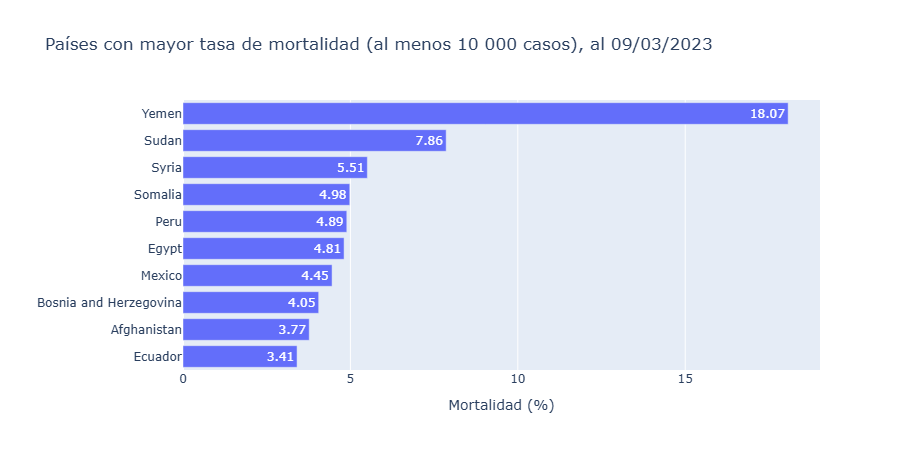

In [18]:
mayor_mortalidad = tablas["Países con mayor tasa de mortalidad"].reset_index()
figura = px.bar(
    mayor_mortalidad.sort_values("mortalidad"), x="mortalidad", y="pais", orientation="h", text_auto=".2f",
    title=f"Países con mayor tasa de mortalidad (al menos {MINIMO:_} casos), al {ULTIMA:%d/%m/%Y}".replace("_", " "),
    labels={"mortalidad": "Mortalidad (%)", "pais": ""},
)
figura.show()

Al 9 de marzo de 2023, Estados Unidos encabeza contagios y muertes (103,8 millones de casos y 1,12 millones de muertes). Entre los países con al menos 10 000 casos, Yemen tiene la mortalidad más alta (18,07 %), muy por encima de Sudán (7,86 %), y Bután la más baja (0,03 %). En recuperación, al 4 de agosto de 2021, encabezan Gabón, Baréin y Catar, todos por encima del 98,8 %; esas cifras dependen de cómo informó cada país sus recuperados, así que conviene leerlas con cautela.

### Tarea 7. Dashboard en Streamlit

La app [p05-dashboard-covid-app.py](p05-dashboard-covid-app.py) reutiliza la lógica de este notebook (`melt`, máximo por provincia y suma por país, división segura, los mismos filtros de los rankings) y añade:

- Carga en caché con `@st.cache_data`, leyendo `Path(__file__).parent / "datos"`; los totales de cada fecha de corte también quedan en caché.
- Barra lateral con la fecha de corte, el mínimo de casos para los rankings de tasas, el número de países por tabla y un interruptor para excluir las entradas que no son países.
- Cuatro métricas, las cinco tablas con `st.column_config` (tasas con dos decimales), la leyenda con el autor y la cita de la fuente.
- Un mapa `px.scatter_geo` por provincia o país a partir de `Lat`/`Long`, sin las filas sin coordenadas.
- Un `st.download_button` con la tabla por país de la fecha de corte en CSV.

Se lanza desde la raíz del repositorio con `uv run streamlit run proyectos/p05-dashboard-covid/p05-dashboard-covid-app.py`. Para el despliegue en Streamlit Community Cloud, la carpeta incluye un [requirements.txt](requirements.txt) mínimo. La celda siguiente la ejecuta con `AppTest` y comprueba que sus rankings coinciden con los de la Tarea 6:

In [19]:
from streamlit.testing.v1 import AppTest

# Silencia el aviso "missing ScriptRunContext", que es normal al ejecutar la app fuera de un servidor
logging.getLogger("streamlit.runtime.scriptrunner_utils.script_run_context").setLevel(logging.ERROR)
# La ruta se resuelve para que AppTest no la busque junto al kernel
app = AppTest.from_file(str(Path("p05-dashboard-covid-app.py").resolve()), default_timeout=120).run()
assert not app.exception, app.exception
print([(metrica.label, metrica.value) for metrica in app.metric])
print(len(app.dataframe), "tablas:", [titulo.value for titulo in app.subheader][:5])

for tabla_app, (titulo, tabla) in zip(app.dataframe, tablas.items()):
    assert tabla_app.value["pais"].tolist() == tabla.index.tolist(), titulo
print("Los cinco rankings de la app coinciden con los del notebook.")

app.date_input[0].set_value(pd.Timestamp("2021-01-31").date()).run()
print("Con corte al 31/01/2021:", [(metrica.label, metrica.value) for metrica in app.metric][:2])

[('Casos confirmados', '676 573 619'), ('Muertes', '6 882 128'), ('Mortalidad global', '1.02 %'), ('Países con casos', '196')]
5 tablas: ['Países con más contagios', 'Países con más decesos', 'Países con mayor tasa de mortalidad', 'Países con menor tasa de mortalidad', 'Países con mayor índice de recuperación']
Los cinco rankings de la app coinciden con los del notebook.


Con corte al 31/01/2021: [('Casos confirmados', '103 324 015'), ('Muertes', '2 323 509')]


La app se ejecuta sin errores, muestra las cinco tablas con los mismos países que este notebook y responde a la fecha de corte: al 31 de enero de 2021, los países sumaban 103 324 015 casos confirmados.

### Conclusiones

- Las series del CSSE parecen sencillas, pero esconden trampas: filas de provincia distintas entre archivos (Canadá), una serie de recuperados que deja de actualizarse el 4 de agosto de 2021, entradas que no son países, cifras oficiales poco creíbles y acumulados que a veces bajan.
- Agregar a nivel país antes de unir, y calcular cada total como máximo por provincia y suma por país, evita perder o duplicar datos; pandas y DuckDB dan exactamente los mismos totales.
- Las tasas necesitan división segura, un mínimo de casos y, en el caso de la recuperación, el mismo corte en el numerador y el denominador.

**Revisión posterior (2026-10):** El proyecto se hizo originalmente en Power BI, leyendo los tres CSV directamente desde el repositorio del CSSE en GitHub, con medidas DAX y el tablero exportado a PDF. Se rehízo en Python con pandas, DuckDB, Plotly y Streamlit, con una copia local de los datos en `datos/`, para que el proyecto no dependa de software de pago ni de Windows; la versión original sigue en el historial de git.